# 1 · What is compared, and on which data

**Question of the paper.** Over Arctic sea ice the turbulent sensible heat flux $H_\mathrm{S}$ is usually
*estimated* with a bulk formula from reanalysis data. How good are such estimates? To find out we need a
*measured* reference. BACSAM-II (Svalbard, April 2024) provides one: a sensor package (the **T-Bird**) towed
about 24 m above the ice below the research aircraft Polar 6, sampling wind and temperature at 100 Hz.
From these data the flux can be measured directly with the **eddy-covariance (EC)** method.

**The logic of the comparison.** All estimates are brought onto the same 5 km flight segments:

| Symbol | How it is obtained | Inputs |
|---|---|---|
| $H_\mathrm{S,obs,EC}$ | eddy covariance — **the reference** | 100 Hz $w$, $\theta$ from the T-Bird |
| $H_\mathrm{S,obs,bulk}$ | bulk formula | measured: KT-19 surface temperature, T-Bird air temperature and wind |
| $H_\mathrm{S,RS,bulk}$ | bulk formula | MODIS surface temperature + ERA5 air temperature and wind |
| $H_\mathrm{S,ERA,bulk}$ | bulk formula | ERA5 only |
| $H_\mathrm{S,ERA,diag}$, $H_\mathrm{S,CAR,diag}$ | taken from the model output | the flux ERA5 / CARRA diagnose themselves |

Going down the table, measured inputs are replaced step by step by products that are available everywhere.
Whatever skill is lost on the way can then be attributed to the input that was replaced.

The chapters follow the paper: **2** how the EC reference is measured · **3** how the bulk method works ·
**4** how the estimates compare · **5** what the result depends on, and how uncertain it is.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
REPO = Path("..").resolve(); sys.path.insert(0, str(REPO))
plt.rcParams.update({"figure.dpi": 110, "figure.constrained_layout.use": True, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

AR  = REPO / "data/observations/ar"
FIG = xr.open_dataset(REPO / "data/model_output/sensitivity_figure_data.nc")      # all flux estimates, 91 segments
SEG = xr.open_dataset(AR / "analysis_ready_polar6_turbulent_fluxes_latest_5km.nc").sel(start_time=FIG.start_time.values)
EC  = FIG["H_obs_ec"].values

## The segments

The analysis uses the low-level legs (T-Bird below 50 m) of the four flight days over sea ice.

In [2]:
t = pd.to_datetime(SEG.start_time.values)
tab = pd.DataFrame({"segments": 1, "T-Bird height (m)": SEG.altitude.values,
                    "EC flux (W m-2)": EC, "KT-19 surface temp. (degC)": SEG.t_kt19.values}, index=t)
g = tab.groupby(tab.index.strftime("%d %B"))
out = g.agg({"segments": "sum", "T-Bird height (m)": "mean", "EC flux (W m-2)": "median", "KT-19 surface temp. (degC)": "mean"}).round(1)
print(f"{len(tab)} segments of 5 km = {5 * len(tab)} km of low-level flight\n"); out

91 segments of 5 km = 455 km of low-level flight



,segments,T-Bird height (m),EC flux (W m-2),KT-19 surface temp. (degC)
13 April,18,21.7,0.2,-25.0
15 April,22,22.1,6.5,-17.1
17 April,26,29.1,0.2,-16.6
23 April,25,21.1,0.0,-2.0


The fluxes are **small**: over compact sea ice in spring the air and the surface have almost the same temperature.
This has a consequence for the whole analysis — with fluxes of a few W m⁻², an estimate that simply predicts
"zero everywhere" already has a small error. Chapter 4 shows why the paper therefore judges the estimates by the
*amplitude* they recover (regression slope) and by their *correlation* with the reference, not by the RMSE.

median 0.4 W m-2, 56 % of the segments within +-2 W m-2


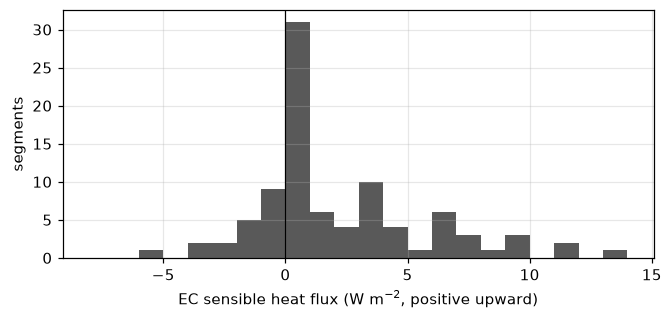

In [3]:
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.hist(EC[np.isfinite(EC)], bins=np.arange(-8, 15, 1), color="0.35")
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("EC sensible heat flux (W m$^{-2}$, positive upward)"); ax.set_ylabel("segments")
print(f"median {np.nanmedian(EC):.1f} W m-2, {np.mean(np.abs(EC[np.isfinite(EC)]) < 2) * 100:.0f} % of the segments within +-2 W m-2")

Flight tracks (Fig. 1 of the paper):

![Fig. 1](../figures_manuscript/output/fig01_campaign_overview.png)